# NeuroOCR: Machine Learning and Deep Learning on Real Handwritten Data

This notebook builds a classical machine-learning baseline and a convolutional
neural network for recognizing handwritten digits. The data comes from the UCI
Optical Recognition of Handwritten Digits dataset distributed with
scikit-learn. A separate held-out test set is used only for final evaluation.

In [1]:
from pathlib import Path
import json
import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, log_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.cnn_numpy import TinyCNN
from src.data import flatten_images, load_real_digits

SEED = 42
np.random.seed(SEED)
print(f"Project root: {ROOT}")
print(f"NumPy version: {np.__version__}")

Project root: /workspace/scratch/cf761f84fa2e/neuroocr-real-world-digit-recognition
NumPy version: 2.3.5


## 1. Load and inspect the real dataset

In [2]:
dataset = load_real_digits(seed=SEED)
split_table = pd.DataFrame(
    {"split": list(dataset.split_sizes), "images": list(dataset.split_sizes.values())}
)
print(dataset.source)
print(f"Image shape: {dataset.X_train.shape[1:]}")
print(f"Pixel range: {dataset.X_train.min():.1f} to {dataset.X_train.max():.1f}")
split_table

UCI Optical Recognition of Handwritten Digits via scikit-learn
Image shape: (8, 8)
Pixel range: 0.0 to 1.0


,split,images
0,train,1257
1,validation,270
2,test,270


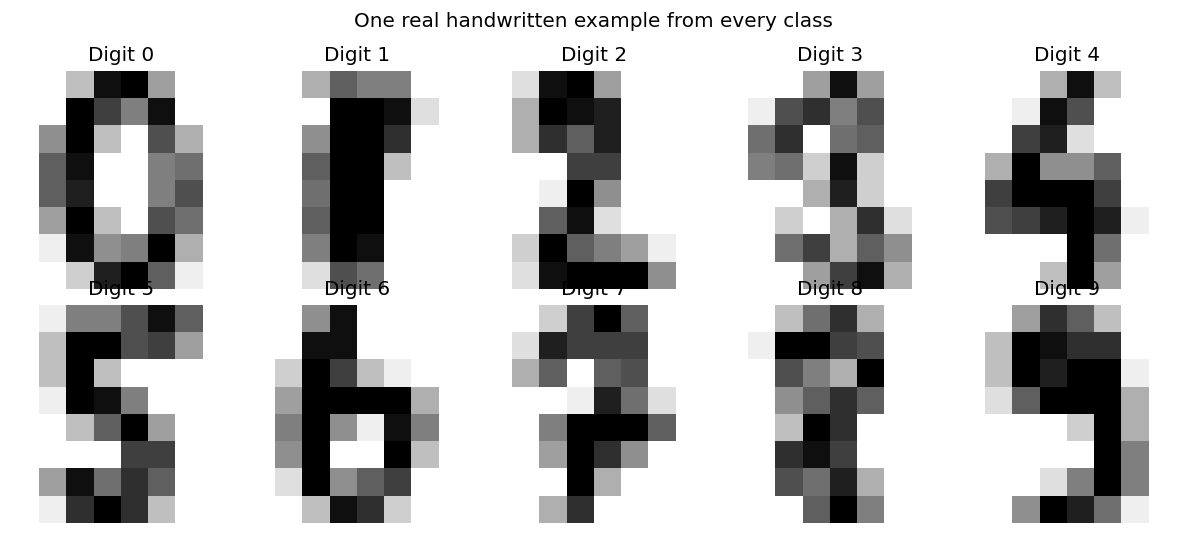

In [3]:
all_images = np.concatenate([dataset.X_train, dataset.X_val, dataset.X_test])
all_labels = np.concatenate([dataset.y_train, dataset.y_val, dataset.y_test])

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for digit, axis in enumerate(axes.flat):
    idx = np.flatnonzero(all_labels == digit)[0]
    axis.imshow(all_images[idx], cmap="gray_r", vmin=0, vmax=1)
    axis.set_title(f"Digit {digit}")
    axis.axis("off")
fig.suptitle("One real handwritten example from every class")
plt.tight_layout()
plt.show()

## 2. Classical machine-learning baseline

In [4]:
ml_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(C=2.0, max_iter=2500, solver="lbfgs", random_state=SEED)),
])

start = time.perf_counter()
ml_model.fit(flatten_images(dataset.X_train), dataset.y_train)
ml_training_seconds = time.perf_counter() - start
ml_probabilities = ml_model.predict_proba(flatten_images(dataset.X_test))
ml_predictions = ml_probabilities.argmax(axis=1)

ml_results = {
    "accuracy": accuracy_score(dataset.y_test, ml_predictions),
    "macro_f1": f1_score(dataset.y_test, ml_predictions, average="macro"),
    "log_loss": log_loss(dataset.y_test, ml_probabilities),
}
print(f"Training time: {ml_training_seconds:.3f} seconds")
pd.Series(ml_results, name="Logistic Regression")

Training time: 0.017 seconds


accuracy    0.974074
macro_f1    0.973848
log_loss    0.111143
Name: Logistic Regression, dtype: float64

## 3. Train the CNN implemented from scratch with NumPy

In [5]:
cnn_model = TinyCNN(conv_filters=16, hidden_dim=64, seed=SEED)
start = time.perf_counter()
history = cnn_model.fit(
    dataset.X_train,
    dataset.y_train,
    dataset.X_val,
    dataset.y_val,
    epochs=70,
    batch_size=64,
    learning_rate=0.0025,
    l2=1e-4,
    patience=12,
    verbose=False,
)
cnn_training_seconds = time.perf_counter() - start
print(f"Completed epochs: {len(history['train_loss'])}")
print(f"Training time: {cnn_training_seconds:.2f} seconds")
print(f"Best validation accuracy: {max(history['val_accuracy']):.2%}")

Completed epochs: 70
Training time: 12.63 seconds
Best validation accuracy: 98.15%


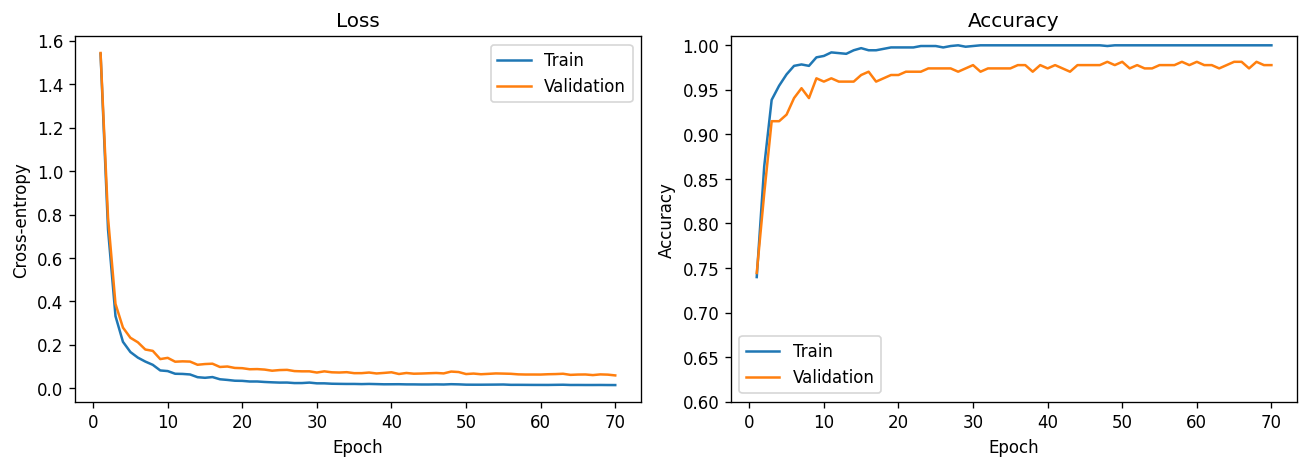

In [6]:
epochs = np.arange(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy")
axes[0].legend()
axes[1].plot(epochs, history["train_accuracy"], label="Train")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0.6, 1.01))
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Compare both models on untouched test images

In [7]:
cnn_probabilities = cnn_model.predict_proba(dataset.X_test)
cnn_predictions = cnn_probabilities.argmax(axis=1)
cnn_results = {
    "accuracy": accuracy_score(dataset.y_test, cnn_predictions),
    "macro_f1": f1_score(dataset.y_test, cnn_predictions, average="macro"),
    "log_loss": log_loss(dataset.y_test, cnn_probabilities),
}

comparison = pd.DataFrame([
    {"model": "Logistic Regression", "family": "Classical ML", **ml_results},
    {"model": "NumPy CNN", "family": "Deep Learning", **cnn_results},
])
comparison.round({"accuracy": 4, "macro_f1": 4, "log_loss": 4})

,model,family,accuracy,macro_f1,log_loss
0,Logistic Regression,Classical ML,0.9741,0.9738,0.1111
1,NumPy CNN,Deep Learning,0.9963,0.9962,0.0363


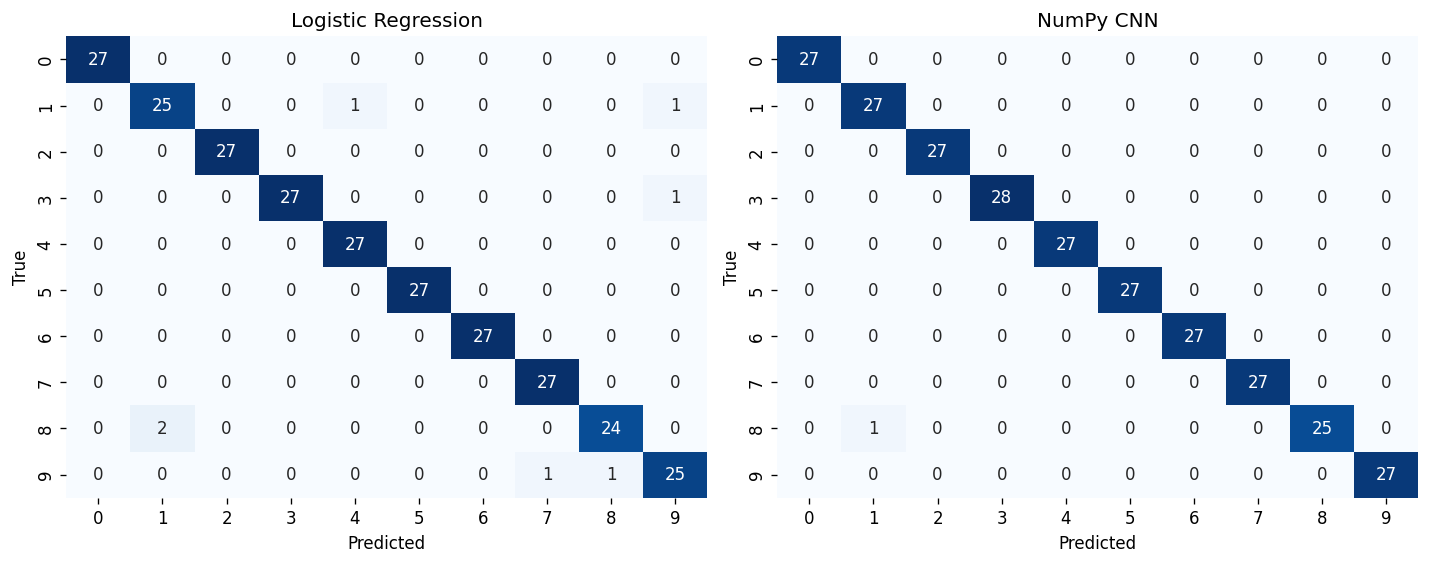

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for axis, predictions, title in [
    (axes[0], ml_predictions, "Logistic Regression"),
    (axes[1], cnn_predictions, "NumPy CNN"),
]:
    sns.heatmap(
        confusion_matrix(dataset.y_test, predictions),
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axis,
    )
    axis.set(title=title, xlabel="Predicted", ylabel="True")
plt.tight_layout()
plt.show()

## 5. Confidence-aware predictions

In [9]:
threshold = 0.85
confidence = cnn_probabilities.max(axis=1)
accepted = confidence >= threshold
coverage = accepted.mean()
accepted_accuracy = (cnn_predictions[accepted] == dataset.y_test[accepted]).mean()

pd.Series({
    "confidence_threshold": threshold,
    "coverage": coverage,
    "accepted_accuracy": accepted_accuracy,
    "images_sent_for_review": int((~accepted).sum()),
})

confidence_threshold       0.850000
coverage                   0.962963
accepted_accuracy          0.996154
images_sent_for_review    10.000000
dtype: float64

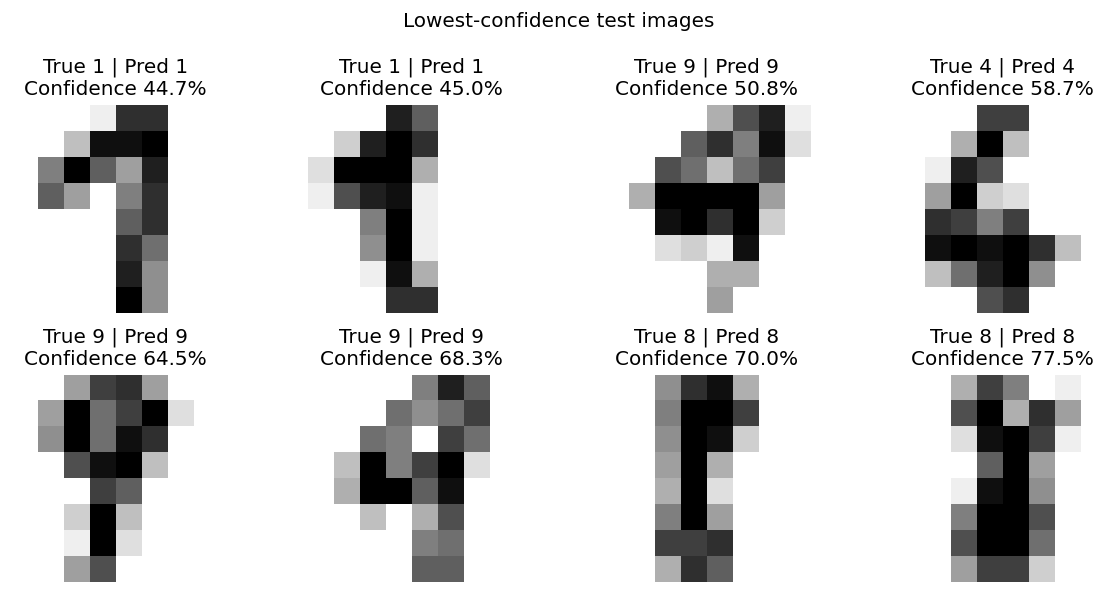

In [10]:
hardest = np.argsort(confidence)[:8]
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for idx, axis in zip(hardest, axes.flat):
    axis.imshow(dataset.X_test[idx], cmap="gray_r", vmin=0, vmax=1)
    axis.set_title(
        f"True {dataset.y_test[idx]} | Pred {cnn_predictions[idx]}\nConfidence {confidence[idx]:.1%}"
    )
    axis.axis("off")
fig.suptitle("Lowest-confidence test images")
plt.tight_layout()
plt.show()

## 6. Explain one decision with input saliency

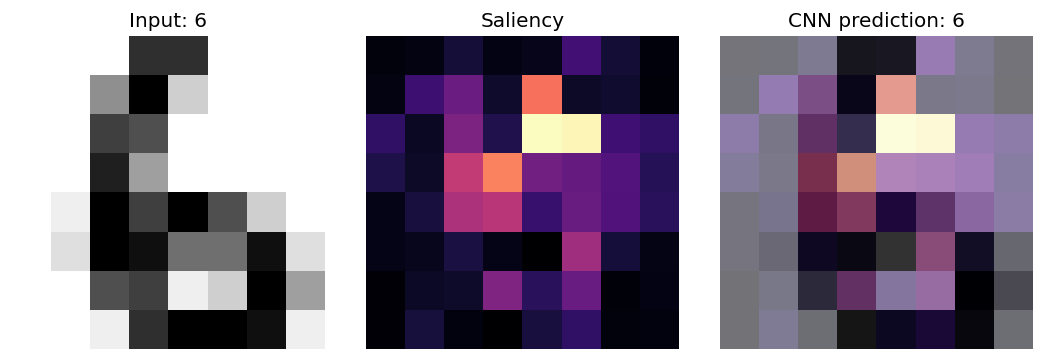

In [11]:
example_index = 0
predicted_digit = int(cnn_predictions[example_index])
saliency = cnn_model.saliency(dataset.X_test[example_index], predicted_digit)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(dataset.X_test[example_index], cmap="gray_r", vmin=0, vmax=1)
axes[0].set_title(f"Input: {dataset.y_test[example_index]}")
axes[1].imshow(saliency, cmap="magma", vmin=0, vmax=1)
axes[1].set_title("Saliency")
axes[2].imshow(dataset.X_test[example_index], cmap="gray_r", vmin=0, vmax=1)
axes[2].imshow(saliency, cmap="magma", alpha=0.55, vmin=0, vmax=1)
axes[2].set_title(f"CNN prediction: {predicted_digit}")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 7. Save reproducible artifacts

In [12]:
model_dir = ROOT / "models"
model_dir.mkdir(exist_ok=True)
joblib.dump(ml_model, model_dir / "logistic_regression.joblib")
cnn_model.save(model_dir / "neuroocr_cnn.npz")

print("Saved:")
print(model_dir / "logistic_regression.joblib")
print(model_dir / "neuroocr_cnn.npz")

Saved:
/workspace/scratch/cf761f84fa2e/neuroocr-real-world-digit-recognition/models/logistic_regression.joblib
/workspace/scratch/cf761f84fa2e/neuroocr-real-world-digit-recognition/models/neuroocr_cnn.npz


## Conclusion

The CNN learned local stroke patterns and outperformed the linear ML baseline on
the held-out test set. The confidence rule adds a practical review path for
ambiguous inputs. The result is a compact educational prototype, not a
production OCR system: deployment on phone photos or multi-digit documents
would require higher-resolution training data, stronger augmentation, drift
monitoring, and a field test.